In [ ]:
import sqlite3
from pathlib import Path
import pandas as pd
import numpy as np

DB_PATH = Path("route_all.db")   

if not DB_PATH.exists():
    raise FileNotFoundError(f"{DB_PATH.resolve()} not found. Fix DB_PATH or move the notebook next to the file.")

conn = sqlite3.connect(DB_PATH)
conn.execute("CREATE INDEX IF NOT EXISTS idx_route ON stoptimes(route)")
conn.commit()

## Quick overview of the database

First and last day in YYYYMMDD format, share realtime *100 percentage of realtime rows

In [4]:
overview = pd.read_sql_query(
    """
    SELECT COUNT(*)                    AS rows,
           COUNT(DISTINCT route)       AS routes,
           COUNT(DISTINCT service_date) AS days,
           MIN(service_date)           AS first_day,
           MAX(service_date)           AS last_day,
           ROUND(AVG(is_realtime), 3)  AS share_realtime
    FROM stoptimes
    """,
    conn,
)
overview

,rows,routes,days,first_day,last_day,share_realtime
0,9069343,391,8,20261010,20261017,0.401


## Loading realtime data

In [6]:
ONLY_REALTIME = True #If you want rows where is_realtime = False change ONLY_REALTIME = False
is_realtime_boolean = False #Change is_realtime from 1/0 to True/False


print("Using all routes in the dataset.")

# --- Query ---
query = """
    SELECT route, trip_id, stop_position, stop_id, scheduled_departure_sec, delay_seconds
    FROM stoptimes
"""
if ONLY_REALTIME:
    query += " WHERE is_realtime = 1" 
query += " ORDER BY route, service_date, trip_id, stop_position"

df = pd.read_sql_query(query, conn)

n_routes = df["route"].nunique()
print(f"{len(df):,} rows, {df.groupby(['route', 'trip_id']).ngroups:,} trips across {n_routes:,} route(s)")

if is_realtime_boolean:
    df["is_realtime"] = df["is_realtime"].astype(bool)

df = df.astype({
    "route": "category",
    "stop_id": "category",
    "trip_id": "category",
    "stop_position": "int16",
    "scheduled_departure_sec": "int32",
    "delay_seconds": "int32",   # NULLs in database appear as 0
})

df.head(10)

Using all routes in the dataset.
3,637,310 rows, 118,733 trips across 362 route(s)


,route,trip_id,stop_position,stop_id,scheduled_departure_sec,delay_seconds
0,102N,HSL:2102N_20261009_La_1_2359,0,HSL:1040273,86340,12
1,102N,HSL:2102N_20261009_La_1_2359,1,HSL:1040233,86400,69
2,102N,HSL:2102N_20261009_La_1_2359,2,HSL:1201129,86580,0
3,102N,HSL:2102N_20261009_La_1_2359,3,HSL:1201131,86640,44
4,102N,HSL:2102N_20261009_La_1_2359,4,HSL:1310101,86760,22
5,102N,HSL:2102N_20261009_La_1_2359,5,HSL:1310105,86820,57
6,102N,HSL:2102N_20261009_La_1_2359,6,HSL:1310124,86880,98
7,102N,HSL:2102N_20261009_La_1_2359,7,HSL:1310198,86940,121
8,102N,HSL:2102N_20261009_La_1_2359,8,HSL:2222205,87060,132
9,102N,HSL:2102N_20261009_La_1_2359,9,HSL:2213236,87120,139


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3637310 entries, 0 to 3637309
Data columns (total 6 columns):
 #   Column                   Dtype   
---  ------                   -----   
 0   route                    category
 1   trip_id                  category
 2   stop_position            int16   
 3   stop_id                  category
 4   scheduled_departure_sec  int32   
 5   delay_seconds            int32   
dtypes: category(3), int16(1), int32(2)
memory usage: 66.6 MB


In [7]:
df.describe()

,stop_position,scheduled_departure_sec,delay_seconds
count,3.637310e+06,3.637310e+06,3.637310e+06
mean,1.734975e+01,5.217467e+04,5.943577e+01
std,1.257596e+01,1.878944e+04,1.395523e+02
min,0.000000e+00,1.410000e+04,-1.643000e+03
25%,7.000000e+00,3.654000e+04,-4.000000e+00
50%,1.500000e+01,5.160000e+04,3.700000e+01
75%,2.500000e+01,6.630000e+04,1.070000e+02
max,9.300000e+01,1.066200e+05,4.294000e+03


## Shape of the data

In [ ]:
df["delay_seconds"].describe() 

count    3.637310e+06
mean     5.943577e+01
std      1.395523e+02
min     -1.643000e+03
25%     -4.000000e+00
50%      3.700000e+01
75%      1.070000e+02
max      4.294000e+03
Name: delay_seconds, dtype: float64

Delay histogram

Full data vs Randomly selected bus lines

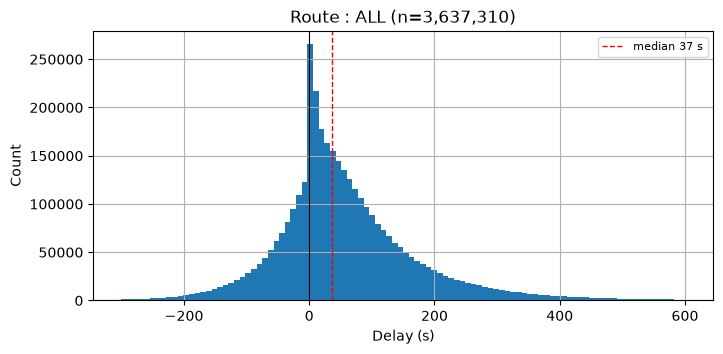

In [ ]:
import matplotlib.pyplot as plt

ax = df["delay_seconds"].hist(bins=100, range=(-300,600), figsize=(8, 3.5))
ax.axvline(df["delay_seconds"].median(), color="red", ls="--", lw=1, label=f"median {df["delay_seconds"].median():.0f} s")
ax.axvline(0, color="black", lw=0.8)  # on time
ax.set_title(f"Route : ALL (n={len(df["delay_seconds"]):,})")
ax.set_xlabel("Delay (s)")
ax.set_ylabel("Count")
ax.legend(fontsize=8)
plt.show()


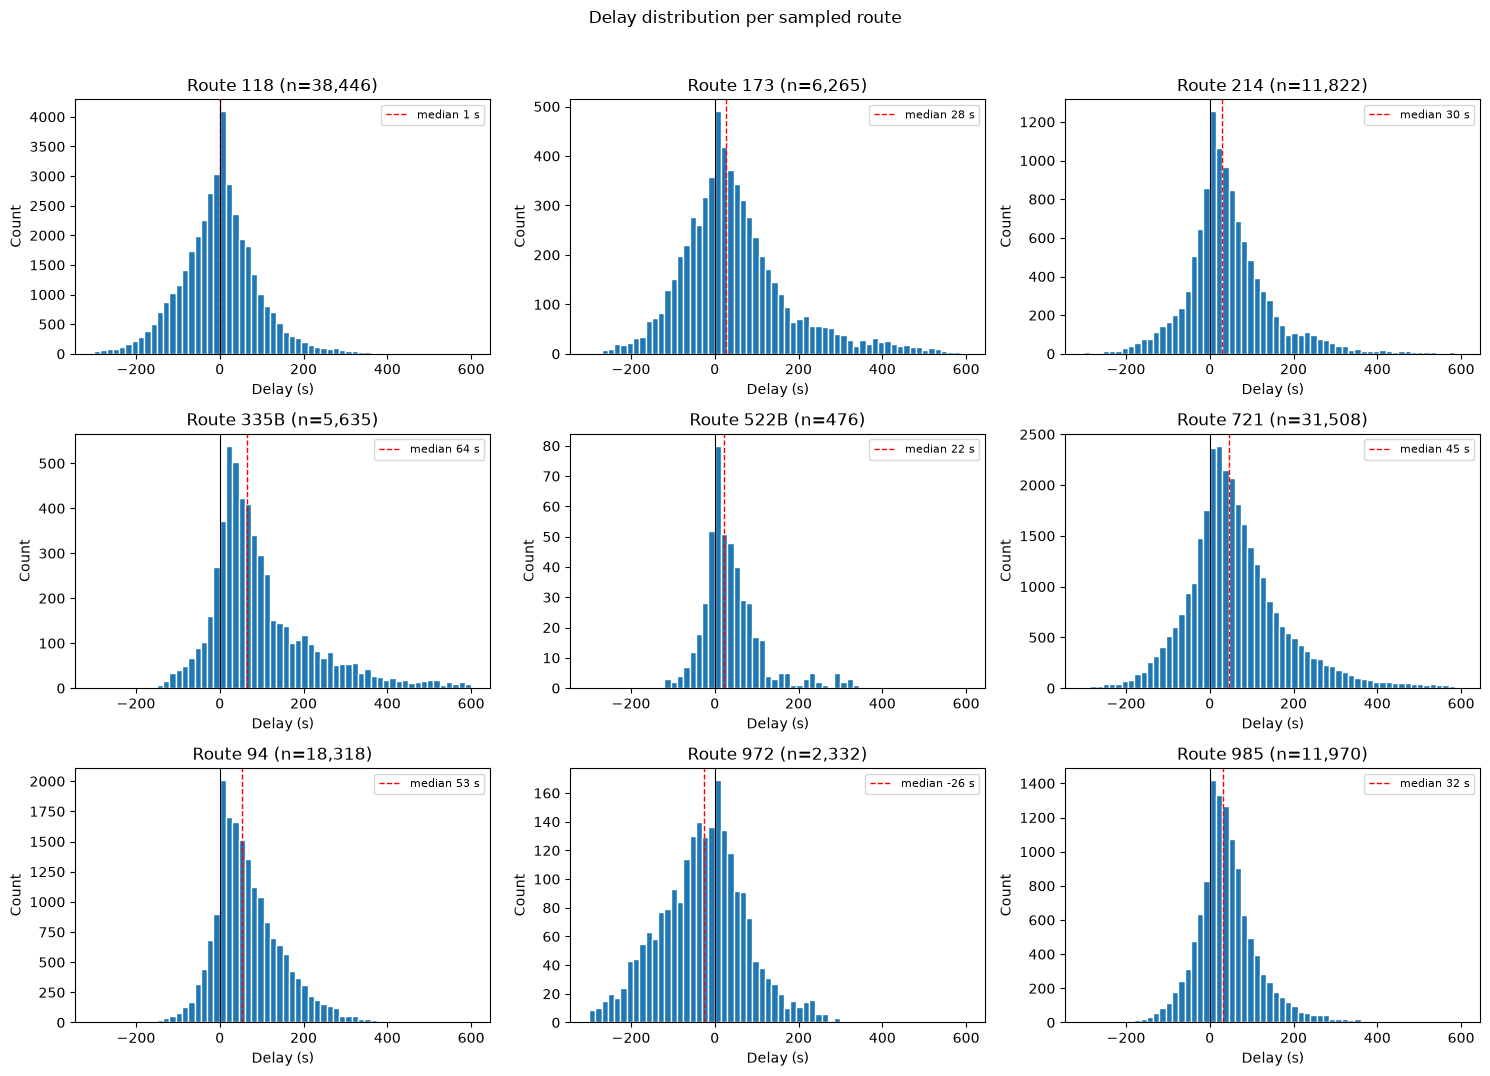

In [ ]:
import random

N_RANDOM = 9         # Number of routes to pick at random from the dataset. None for the whole dataset
RANDOM_SEED = 59   # Set a number for reproducibility

all_routes = sorted(df["route"].unique())
sample_routes = random.Random(RANDOM_SEED).sample(all_routes, min(N_RANDOM, len(all_routes)))

df_sample = df[df["route"].isin(sample_routes)].copy()
df_sample["route"] = df_sample["route"].cat.remove_unused_categories()

RANGE_MIN, RANGE_MAX = -300, 600   # display range in seconds
N_BINS = 60

routes = sorted(df_sample["route"].unique())
n = len(routes)
ncols = min(3, n)
nrows = int(np.ceil(n / ncols))
bins = np.linspace(RANGE_MIN, RANGE_MAX, N_BINS + 1)  # same bins for every route, so they're comparable

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), sharex=False, squeeze=False)

for ax, route in zip(axes.flat, routes):
    d = df_sample.loc[df_sample["route"] == route, 'delay_seconds']
    ax.hist(d, bins=bins, edgecolor="white")
    ax.axvline(d.median(), color="red", ls="--", lw=1, label=f"median {d.median():.0f} s")
    ax.axvline(0, color="black", lw=0.8)  # on time
    ax.set_title(f"Route {route} (n={len(d):,})")
    ax.set_xlabel("Delay (s)")
    ax.set_ylabel("Count")
    ax.legend(fontsize=8)

for ax in axes.flat[n:]:  # hide unused panels
    ax.axis("off")

fig.suptitle("Delay distribution per sampled route", y=1.02)
fig.tight_layout()
plt.show()

## Helping columns

In [ ]:
def direction(trip):
    return str(trip).split("_")[3]
def weekday(trip):
    return str(trip).split("_")[2]
def time(trip):
    hhmm = str(trip).split("_")[4]
    return (int(hhmm[:2]) * 3600 + int(hhmm[2:4]) * 60 )// 3600
    
df["direction"] = df["trip_id"].apply(direction).astype('category')
df["hour"] = df["trip_id"].apply(time).astype('int16')
df["weekday"] = df["trip_id"].apply(weekday).astype('category')

df.head()

,service_date,route,trip_id,stop_position,stop_id,scheduled_departure_sec,delay_seconds,is_realtime,direction,hour,weekday
0,20261010,102N,HSL:2102N_20261009_La_1_2359,0,HSL:1040273,86340,12,1,1,23,La
1,20261010,102N,HSL:2102N_20261009_La_1_2359,1,HSL:1040233,86400,69,1,1,23,La
2,20261010,102N,HSL:2102N_20261009_La_1_2359,2,HSL:1201129,86580,0,1,1,23,La
3,20261010,102N,HSL:2102N_20261009_La_1_2359,3,HSL:1201131,86640,44,1,1,23,La
4,20261010,102N,HSL:2102N_20261009_La_1_2359,4,HSL:1310101,86760,22,1,1,23,La


## Delay per day of the week

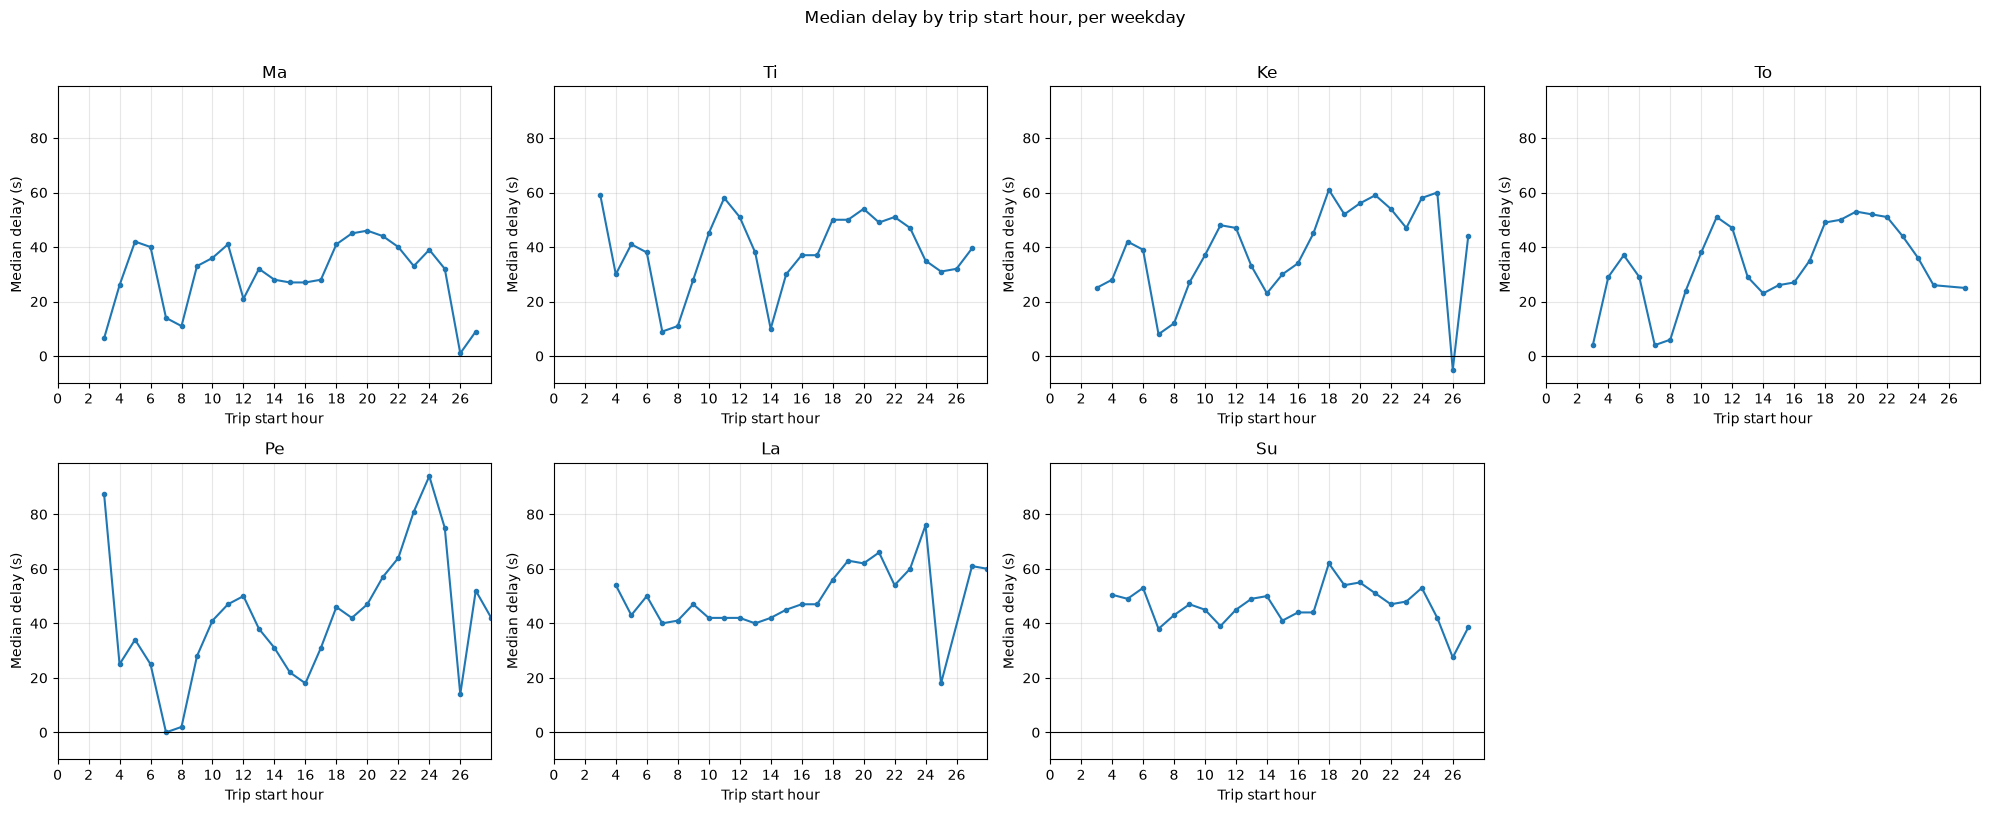

In [ ]:
DAYS = ["Ma", "Ti", "Ke", "To", "Pe", "La", "Su"]

d = pd.DataFrame({
    "dow": df["weekday"].astype(str),
    "hour": df["hour"],
    "delay_seconds": df["delay_seconds"],
})

med = d.groupby(["dow", "hour"], observed=True)["delay_seconds"].median().unstack("dow").reindex(columns=DAYS)

fig, axes = plt.subplots(2, 4, figsize=(20, 8), squeeze=False)
ymin, ymax = med.min().min(), med.max().max()
pad = 0.05 * ((ymax - ymin) or 1)

for ax, day in zip(axes.flat, DAYS):
    s = med[day].dropna()
    ax.plot(s.index, s.values, marker="o", ms=3, lw=1.5)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(day)
    ax.set_xlim(0, 28)
    ax.set_ylim(ymin - pad, ymax + pad)
    ax.set_xticks(range(0, 28, 2))
    ax.tick_params(labelbottom=True)
    ax.set_xlabel("Trip start hour")
    ax.set_ylabel("Median delay (s)")
    ax.grid(alpha=0.3)

axes.flat[7].axis("off")   # no 8th panel

fig.suptitle("Median delay by trip start hour, per weekday", y=1.01)
fig.tight_layout()
plt.show()

Weekday vs Weekend

In [ ]:
def is_weekend (weekday):
    if weekday  in ['La', 'Su']:
        return 1
    elif weekday in ['Ma', 'Ti', 'Ke', 'To', 'Pe']:
        return 0
    else:
        return pd.NA

df['is_weekend'] = df['weekday'].apply(is_weekend).astype('int8')

df.head(5)

,service_date,route,trip_id,stop_position,stop_id,scheduled_departure_sec,delay_seconds,is_realtime,direction,hour,weekday,is_weekend
0,20261010,102N,HSL:2102N_20261009_La_1_2359,0,HSL:1040273,86340,12,1,1,23,La,1
1,20261010,102N,HSL:2102N_20261009_La_1_2359,1,HSL:1040233,86400,69,1,1,23,La,1
2,20261010,102N,HSL:2102N_20261009_La_1_2359,2,HSL:1201129,86580,0,1,1,23,La,1
3,20261010,102N,HSL:2102N_20261009_La_1_2359,3,HSL:1201131,86640,44,1,1,23,La,1
4,20261010,102N,HSL:2102N_20261009_La_1_2359,4,HSL:1310101,86760,22,1,1,23,La,1


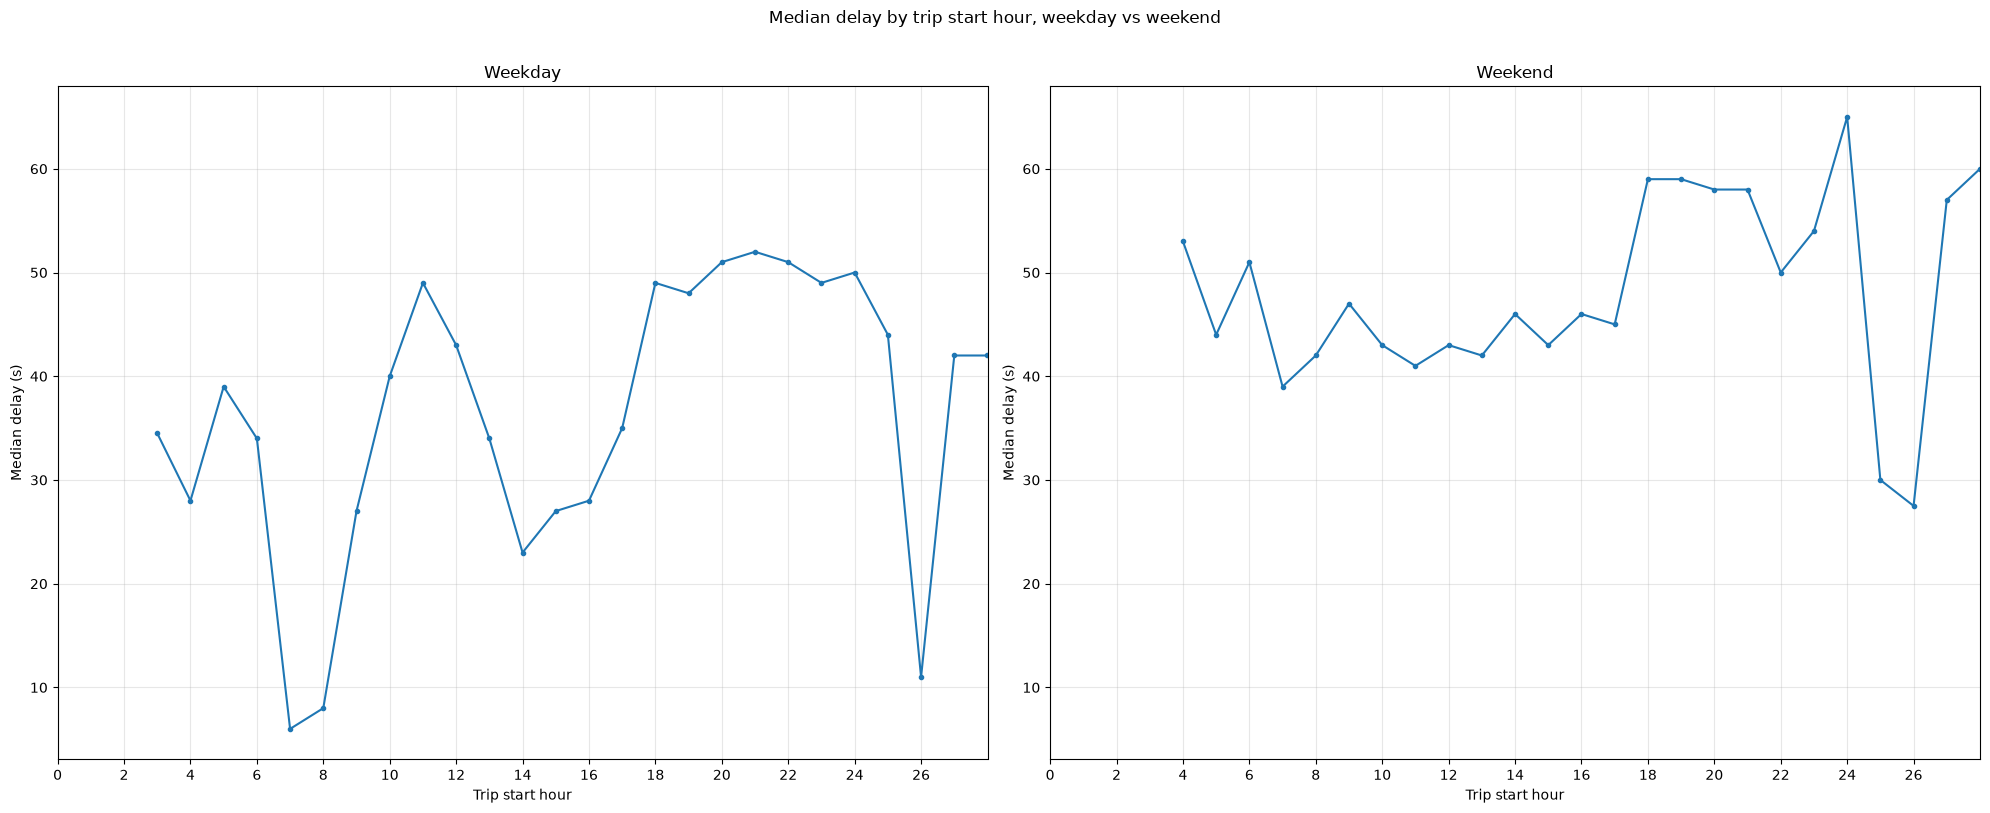

In [ ]:
WE_MAP = {0: "Weekday", 1: "Weekend"}
WE = list(WE_MAP.values())

d = pd.DataFrame({
    "is_we": df["is_weekend"].map(WE_MAP).astype(str),
    "hour": df["hour"],
    "delay_seconds": df["delay_seconds"],
})

med = d.groupby(["is_we", "hour"], observed=True)["delay_seconds"].median().unstack("is_we").reindex(columns=WE)

fig, axes = plt.subplots(1, 2, figsize=(20, 8), squeeze=False)
ymin, ymax = med.min().min(), med.max().max()
pad = 0.05 * ((ymax - ymin) or 1)

for ax, day in zip(axes.flat, WE):
    s = med[day].dropna()
    ax.plot(s.index, s.values, marker="o", ms=3, lw=1.5)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(day)
    ax.set_xlim(0, 28)
    ax.set_ylim(ymin - pad, ymax + pad)
    ax.set_xticks(range(0, 28, 2))
    ax.tick_params(labelbottom=True)
    ax.set_xlabel("Trip start hour")
    ax.set_ylabel("Median delay (s)")
    ax.grid(alpha=0.3)

fig.suptitle("Median delay by trip start hour, weekday vs weekend", y=1.01)
fig.tight_layout()
plt.show()